[![Obre a Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# Nom i NIU

`Adrián Valverde Ambrosio` · `NIU: 1707952`

# Problema 1 · Encoding i NaNs

> **Pregunta forta**  
> Què hi ha amagat darrere de convertir buits i categories en un número?


En aquesta entrega convertireu dades reals i imperfectes (amb buits i amb text) en una matriu `X` defensable. Encara no busqueu "el millor model": busqueu una representació que pugueu justificar.

Treballareu amb el dataset House Prices de Kaggle (`train.csv`). Poseu el fitxer al costat del notebook (a Colab, pugeu-lo o munteu el Drive).

**Contracte de l'entrega:** cada decisió de representació (com tracteu un `NaN`, com codifiqueu una categoria) ha de venir acompanyada d'evidència, del risc que assumiu i, quan calgui, d'una condició de no-ús.

*Referències: LlibreAPC (Gonzalez Sabaté) §3.5 Tipus de Dades i Codificació, §3.6 Selecció d'Atributs, §7.4 Data Leakage.*

(Afegiu el nombre de cel·les que sigui necessari per estructurar adequadament el vostre codi i comentaris.)


## Com s'avalua

Aquesta entrega es puntua **sobre 10**, a partir dels quatre exercicis: **Exercici 1 (2 punts) · Exercici 2 (2) · Exercici 3 (2) · Exercici 4 (4)**. La nota s'incorpora al portafolis individual del curs.

A cada exercici no es valora només que el codi funcioni, sinó que la **decisió sigui defensable**: concepte ben connectat, protocol sense leakage (`fit` només amb train), interpretació dels resultats, i decisió amb evidència, risc i límit.

**Regla d'or (anti-leakage, §7.4):** qualsevol número que surti de les dades (l'estadístic amb què ompliu un buit, les categories que coneix un encoder, el llindar del vostre detector) es calcula **només amb train**. El *test* es consulta una sola vegada, al final. Aquesta regla val per a les quatre entregues del curs; a partir d'ara només us recordarem què s'hi afegeix cada setmana.


# Exercicis a entregar

### Exercici 1 (2 punts): detector "a cegues" de variables categòriques

Definiu i implementeu un mètode estadístic per decidir si una columna és **categòrica** sense veure'n el nom.

El vostre detector s'ha de comprovar sobre aquestes sis columnes d'Ames, que per a `pandas` són totes numèriques: `MSSubClass`, `OverallQual`, `LotArea`, `YearBuilt`, `MoSold` i `Id`. Digueu quina classificació els dona el vostre mètode, quina us sembla discutible i per què.

Justifiqueu cada llindar que feu servir: d'on surt el número i què passaria si el moguéssiu.

**Prediu abans d'executar:** quantes columnes del dataset espereu que el vostre mètode marqui com a categòriques? Escriviu-ho abans de córrer el codi.

Apliqueu el mètode a tot el dataset.

**Predicció abans d'executar:** el dataset té 43 columnes de text, que ja són categòriques. A més, espero que unes 10-15 columnes numèriques siguin en realitat codis o comptadors amb pocs valors (qualitats, nombre de banys, mes...). Aposto per **unes 55 categòriques** en total.

**Mètode:** una columna és
- **categòrica** si és de text, o si tots els valors són enters i n'hi ha **20 o menys** de diferents;
- **identificador** si és entera i té un valor diferent per a cada fila (no és ni categòrica ni numèrica: s'ha d'excloure);
- **numèrica** en cas contrari.

In [1]:
# Importació de llibreries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Càrrega del dataset (train.csv)
df = pd.read_csv('train.csv')
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
# Detector 'a cegues' de variables categòriques
LLINDAR = 20   # nombre màxim de valors diferents perquè una columna entera sigui categòrica

def tipus_columna(col, llindar=LLINDAR):
    x = col.dropna()
    if not pd.api.types.is_numeric_dtype(x):   # text
        return 'categòrica'
    n_unics = x.nunique()
    enters = np.all(x == np.round(x))
    if enters and n_unics == len(x):          # un valor diferent per fila -> identificador
        return 'identificador'
    if enters and n_unics <= llindar:         # pocs valors enters -> codis / nivells
        return 'categòrica'
    return 'numèrica'

sis = ['MSSubClass', 'OverallQual', 'LotArea', 'YearBuilt', 'MoSold', 'Id']
taula = pd.DataFrame({'valors_diferents': [df[c].nunique() for c in sis],
                      'detector': [tipus_columna(df[c]) for c in sis]}, index=sis)
display(taula)

# Tot el dataset
resultat = df.drop(columns='SalePrice').apply(tipus_columna)
print(resultat.value_counts())
num_marcades = [c for c in df.select_dtypes('number') if resultat.get(c) == 'categòrica']
print('Numèriques per a pandas però categòriques pel detector:', num_marcades)

# Sensibilitat al llindar
for l in [5, 10, 15, 20, 30, 50]:
    r = df.drop(columns='SalePrice').apply(lambda c: tipus_columna(c, l))
    print(f'llindar={l:>2}: {(r == "categòrica").sum()} categòriques')

,valors_diferents,detector
MSSubClass,15,categòrica
OverallQual,10,categòrica
LotArea,1073,numèrica
YearBuilt,112,numèrica
MoSold,12,categòrica
Id,1460,identificador


categòrica       59
numèrica         20
identificador     1
Name: count, dtype: int64
Numèriques per a pandas però categòriques pel detector: ['MSSubClass', 'OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', '3SsnPorch', 'PoolArea', 'MoSold', 'YrSold']
llindar= 5: 51 categòriques
llindar=10: 55 categòriques
llindar=15: 58 categòriques
llindar=20: 59 categòriques
llindar=30: 61 categòriques


llindar=50: 61 categòriques


**Resultat a les sis columnes:**

| Columna | Valors diferents | Detector | Comentari |
|---|---|---|---|
| `MSSubClass` | 15 | categòrica | Correcte: són codis de tipus d'habitatge (20, 60, 190...); la distància entre codis no vol dir res. |
| `OverallQual` | 10 | categòrica | **Discutible**: és ordinal (1-10). Es pot tractar com a numèrica perquè l'ordre i el pas són raonables. |
| `LotArea` | 1073 | numèrica | Correcte. |
| `YearBuilt` | 112 | numèrica | Correcte, és una magnitud contínua en el temps. |
| `MoSold` | 12 | categòrica | **Discutible**: és cíclica (Exercici 2); ni lineal ni one-hot del tot. |
| `Id` | 1460 | identificador | Correcte: un valor per fila, no aporta informació i s'ha d'excloure. |

Sobre tot el dataset en surten **59 categòriques** (43 de text + 16 numèriques), 20 numèriques i 1 identificador. La predicció (≈55) era propera: ens hem descomptat en els comptadors, que no havíem previst (`BsmtHalfBath`, `KitchenAbvGr`, `PoolArea`, `3SsnPorch`).

**Decisió (evidència · risc · límit):**
- **Evidència / llindar:** el 20 surt de mirar quants nivells tenen les codificacions habituals (mesos = 12, qualitats = 10, `MSSubClass` = 15) i quants té una variable contínua real (anys > 100, àrees > 300). La sensibilitat ho confirma: amb llindar 5 en surten 51, amb 10 en surten 55, amb 15 en surten 58 i de 20 a 50 gairebé no canvia (59 → 61). Per sota de 15 perdríem `MSSubClass` (15 valors) i `MoSold` (12); per sobre de 30 començaríem a marcar variables contínues amb pocs valors observats.
- **Risc:** falsos positius en **comptadors** (`FullBath`, `GarageCars`, `Fireplaces`) i en columnes gairebé sempre a zero (`PoolArea`, `3SsnPorch`), que són numèriques però tenen pocs valors. Falsos negatius en categòriques amb molts nivells (un codi postal tindria centenars de valors i el marcaria numèric).
- **Límit / no-ús:** no el faria servir com a decisió automàtica en datasets petits (amb 50 files quasi tot té < 20 valors) ni amb codis de molts nivells. És un filtre inicial que s'ha de revisar a mà amb `data_description.txt`.

### Exercici 2 (2 punts): encoding de variables cícliques

Els dies de la setmana i els mesos de l'any són categories amb un ordre que **es tanca**: després de diumenge torna dilluns.

**1.** Codifiqueu els dies de la setmana com `dilluns = 0, dimarts = 1, ..., diumenge = 6` i calculeu la taula de distàncies entre tots els parells de dies.

**2.** Mireu la taula i digueu què hi ha que no us agrada. 

**3.** Proposeu, implementeu i defenseu una codificació que ho arregli. Torneu a ensenyar la taula de distàncies amb la vostra codificació i expliqueu què heu guanyat.

**Decisió (evidència · risc · límit):** justifiqueu la resposta amb la idea de **distància**. Quina geometria imposa cada codificació i quan seria inadequada?

Distàncies amb la codificació 0..6


,dilluns,dimarts,dimecres,dijous,divendres,dissabte,diumenge
dilluns,0,1,2,3,4,5,6
dimarts,1,0,1,2,3,4,5
dimecres,2,1,0,1,2,3,4
dijous,3,2,1,0,1,2,3
divendres,4,3,2,1,0,1,2
dissabte,5,4,3,2,1,0,1
diumenge,6,5,4,3,2,1,0


Distàncies amb la codificació (sin, cos)


,dilluns,dimarts,dimecres,dijous,divendres,dissabte,diumenge
dilluns,0.00,0.87,1.56,1.95,1.95,1.56,0.87
dimarts,0.87,0.00,0.87,1.56,1.95,1.95,1.56
dimecres,1.56,0.87,0.00,0.87,1.56,1.95,1.95
dijous,1.95,1.56,0.87,0.00,0.87,1.56,1.95
divendres,1.95,1.95,1.56,0.87,0.00,0.87,1.56
dissabte,1.56,1.95,1.95,1.56,0.87,0.00,0.87
diumenge,0.87,1.56,1.95,1.95,1.56,0.87,0.00


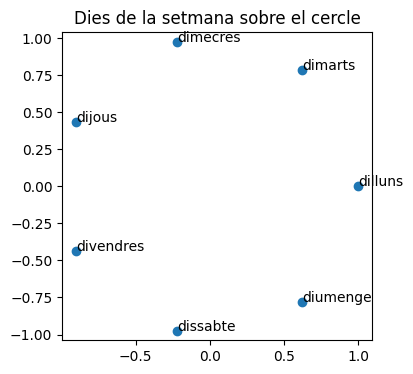

In [3]:
# Encoding de variables temporals (cíclic)
dies = ['dilluns', 'dimarts', 'dimecres', 'dijous', 'divendres', 'dissabte', 'diumenge']
k = np.arange(7)

# 1. Codificació lineal 0..6
lineal = k.reshape(-1, 1)
dist_lineal = np.abs(lineal - lineal.T)
print('Distàncies amb la codificació 0..6')
display(pd.DataFrame(dist_lineal, index=dies, columns=dies))

# 3. Codificació cíclica: cada dia és un punt d'un cercle (sin, cos)
angle = 2 * np.pi * k / 7
ciclic = np.c_[np.sin(angle), np.cos(angle)]
dist_ciclic = np.sqrt(((ciclic[:, None, :] - ciclic[None, :, :]) ** 2).sum(axis=2))
print('Distàncies amb la codificació (sin, cos)')
display(pd.DataFrame(dist_ciclic, index=dies, columns=dies).round(2))

# Mateixa idea per als mesos de l'any (MoSold), per fer-la servir al dataset
df['MoSold_sin'] = np.sin(2 * np.pi * (df['MoSold'] - 1) / 12)
df['MoSold_cos'] = np.cos(2 * np.pi * (df['MoSold'] - 1) / 12)
plt.figure(figsize=(4, 4))
plt.scatter(ciclic[:, 1], ciclic[:, 0])
for d, (s, c) in zip(dies, ciclic):
    plt.annotate(d, (c, s))
plt.title('Dies de la setmana sobre el cercle'); plt.axis('equal'); plt.show()

**2. Què no ens agrada de la taula lineal:** la distància entre **diumenge i dilluns és 6**, la màxima de la taula, quan en realitat són dies consecutius (distància 1). La codificació 0..6 diu que dilluns i diumenge són els dies més diferents de la setmana.

**3. Proposta: codificació cíclica (sin, cos).** Cada dia és un punt d'un cercle: $(\sin(2\pi k/7), \cos(2\pi k/7))$. Ara diumenge-dilluns val 0.87, igual que qualsevol parell de dies consecutius, i la distància màxima (1.95) és entre dies separats 3 o 4 posicions. La taula és simètrica "en cercle": cada fila és la mateixa desplaçada.

**Decisió (evidència · risc · límit):**
- **Evidència:** la codificació lineal imposa una **recta** (distància = |i − j|), i trenca la veïnatge de diumenge-dilluns. La cíclica imposa un **cercle**: la distància només depèn de quants dies hi ha entre ells, en el sentit més curt. Fem servir 2 columnes perquè amb una sola (només sin) dos dies diferents donarien el mateix valor.
- **Risc:** ocupa dues columnes que només tenen sentit juntes (un arbre que en miri una sola perd la idea). I la distància no és proporcional als dies (1 dia = 0.87, 3 dies = 1.95), és la corda del cercle.
- **Límit / no-ús:** seria inadequada si el que importa no és la proximitat sinó un efecte concret d'un dia (p. ex. "dissabte és especial"), on el one-hot és millor; o si la variable no es tanca realment (anys: 2010 no torna a 2006). També l'apliquem a `MoSold` (desembre i gener queden a prop).

### Exercici 3 (2 punts): imputació en sèries temporals de sensors

Teniu enregistrada la sèrie sencera d'un sensor, una lectura per minut, amb trams de lectures perdudes. L'analitzeu *a posteriori*: no heu de predir res en temps real, teniu tota la sèrie al davant.

La sèrie és al fitxer `sensor.csv`, al costat d'aquest notebook. Tots partiu exactament de les mateixes dades, o sigui que els vostres números són comparables entre vosaltres.

**1. La resposta de partida.** Abans de tocar cap dada, escriviu la resposta de la qual partiu: com ompliríeu aquests buits, i d'on surt.

**2. La comprovació.** Implementeu-la sobre la sèrie, implementeu com a mínim una alternativa, i mesureu-les totes dues amagant lectures que ja coneixeu i comparant el valor imputat amb el real. Proveu-ho amb trams perduts de llargades diferents, no només d'una lectura.

**3. L'auditoria.** Compareu els resultats amb la resposta de partida i responeu quatre coses:

* en què encertava,
* en què s'equivocava,
* què no podia saber sense mirar aquestes dades,
* i quan hauria estat la resposta bona: què li passaria al vostre mètode *en producció*, amb les lectures arribant una a una i la següent encara sense existir?


**1. Resposta de partida (abans de tocar les dades):** ompliria els forats amb **interpolació lineal** entre l'última lectura abans del forat i la primera després. Surt de la idea que la temperatura és una magnitud física que canvia lentament minut a minut, i com que analitzem la sèrie *a posteriori* tenim els dos extrems del forat. Esperaria que funcioni molt bé per a forats curts i pitjor per a forats llargs, on la temperatura pot pujar i baixar pel mig.

In [4]:
# La serie del sensor. Es al fitxer sensor.csv, al costat d'aquest notebook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

sensor = (pd.read_csv('sensor.csv', parse_dates=['timestamp'])
            .set_index('timestamp')['temp_c'])

print('lectures:', len(sensor), '| NaN:', int(sensor.isna().sum()),
      '(%.1f%%)' % (100 * sensor.isna().mean()))


lectures: 10080 | NaN: 1164 (11.5%)


MAE (°C) segons la llargada del forat


,lineal (partida),ffill,perfil diari
llargada (min),,,
1,0.037,0.057,0.037
5,0.054,0.089,0.054
20,0.088,0.132,0.088
60,0.112,0.373,0.110
180,0.189,0.993,0.165


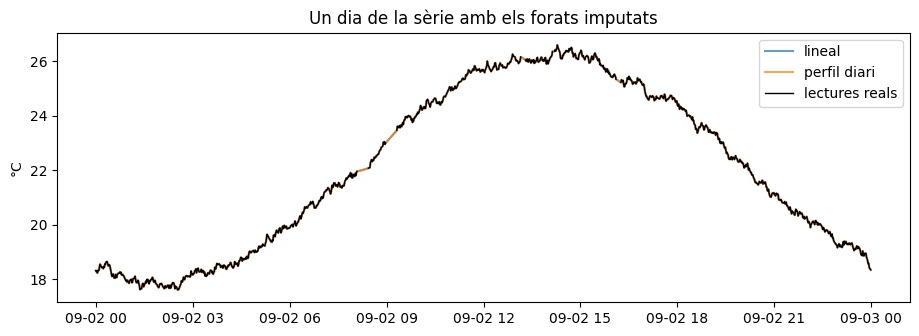

In [5]:
# La resposta de partida, les dues imputacions i la mesura
# Resposta de partida: interpolació lineal entre l'última lectura abans del forat i la primera després.
# Alternatives: repetir l'últim valor (ffill) i "perfil diari + interpolació del residu".

def imputa_lineal(s):
    return s.interpolate(method='time', limit_direction='both')

def imputa_ffill(s):
    return s.ffill().bfill()

def imputa_perfil(s):
    # perfil mitjà per minut del dia, calculat només amb les lectures visibles,
    # suavitzat amb una finestra circular de ±60 min (amb 7 dies, la mitjana d'un sol minut és sorollosa)
    w = 60
    minut = s.index.hour * 60 + s.index.minute
    p = s.groupby(minut).mean()
    p = pd.concat([p.iloc[-w:], p, p.iloc[:w]]).rolling(2 * w + 1, center=True, min_periods=1).mean().iloc[w:-w]
    perfil = pd.Series(p.reindex(minut).values, index=s.index)
    residu = (s - perfil).interpolate(method='time', limit_direction='both')
    return perfil + residu

metodes = {'lineal (partida)': imputa_lineal, 'ffill': imputa_ffill, 'perfil diari': imputa_perfil}

# Amaguem trams de lectures CONEGUDES i comparem amb el valor real
rng = np.random.default_rng(RANDOM_STATE)
conegut = sensor.notna().values
files = []
for llargada in [1, 5, 20, 60, 180]:
    errors = {m: [] for m in metodes}
    for rep in range(30):
        # tria un tram on totes les lectures són conegudes
        while True:
            ini = rng.integers(1, len(sensor) - llargada - 1)
            if conegut[ini - 1: ini + llargada + 1].all():
                break
        amagada = sensor.copy()
        amagada.iloc[ini: ini + llargada] = np.nan      # el mètode no veu el valor real
        real = sensor.iloc[ini: ini + llargada]
        for m, f in metodes.items():
            pred = f(amagada).iloc[ini: ini + llargada]
            errors[m].append(np.abs(pred - real).mean())
    files.append({'llargada (min)': llargada, **{m: np.mean(e) for m, e in errors.items()}})

mae = pd.DataFrame(files).set_index('llargada (min)')
print('MAE (°C) segons la llargada del forat')
display(mae.round(3))

# Imputació final de la sèrie i figura d'un dia
sensor_imp = imputa_perfil(sensor)
dia = slice('2026-09-02', '2026-09-02')
plt.figure(figsize=(11, 3.5))
plt.plot(imputa_lineal(sensor)[dia], label='lineal', alpha=.7)
plt.plot(sensor_imp[dia], label='perfil diari', alpha=.7)
plt.plot(sensor[dia], 'k', lw=1, label='lectures reals')
plt.legend(); plt.ylabel('°C'); plt.title('Un dia de la sèrie amb els forats imputats'); plt.show()

**2. Comprovació.** Hem comparat tres mètodes amagant 30 trams de lectures conegudes per a cada llargada (1, 5, 20, 60 i 180 min):
- **lineal** (resposta de partida),
- **ffill** (repetir l'últim valor),
- **perfil diari**: la forma mitjana del dia (calculada amb les lectures visibles i suavitzada) més la interpolació lineal de la diferència respecte d'aquesta forma.

**3. Auditoria:**
- **En què encertava:** la interpolació lineal és molt bona per a forats curts (MAE 0.04 °C a 1 min, 0.09 °C a 20 min) i molt millor que el ffill (a 180 min, 0.19 contra 0.99 °C).
- **En què s'equivocava:** en forats llargs (≥ 60 min) la recta talla la corba del cicle diari (a les hores de pujada o baixada de temperatura). El perfil diari ho millora: 0.165 contra 0.189 °C a 180 min (≈13% menys error). En forats curts tots dos empaten.
- **Què no podia saber sense mirar les dades:** que la sèrie té un **cicle diari** molt marcat (17 °C de matinada, 25 °C a les 13 h), quina llargada tenen els forats reals (de 1 a 180 min) i que el perfil s'havia de suavitzar (amb només 7 dies, la mitjana d'un minut concret és sorollosa: la primera versió sense suavitzar donava més error que la lineal).
- **En producció:** amb les lectures arribant una a una, **la interpolació no es pot fer** perquè la lectura de després del forat encara no existeix (faria servir el futur). Allà la resposta bona seria el ffill o el perfil diari sense residu futur (perfil + últim residu conegut). La interpolació només és vàlida en anàlisi *a posteriori*.

**Decisió (evidència · risc · límit):**
- **Evidència:** faria servir el **perfil diari + interpolació del residu**: empata amb la lineal en forats curts i és el millor en forats llargs (taula de MAE). El ffill queda descartat.
- **Leakage en la mesura:** els valors amagats es posen a `NaN` **abans** de cridar el mètode, de manera que ni la interpolació ni el càlcul del perfil diari els veuen; només comparem al final. Hem vigilat que els trams amagats fossin de lectures conegudes (sense NaN reals al voltant) per tenir sempre un valor real per comparar, i que el perfil es calculés dins de la funció amb la sèrie ja tapada.
- **Límit:** la conclusió val per a forats de fins a 3 h en una sèrie amb un cicle diari estable. Deixaria de ser vàlida amb forats de dies sencers (el perfil de 7 dies no aguanta), si hi ha un canvi de règim (ona de calor, avaria) o en temps real (no hi ha extrem dret).

### Exercici 4 (4 punts): avaluació objectiva de la imputació

Com podeu mesurar si una imputació encerta, si el valor real no hi és? La sortida és amagar valors que **sí que** coneixeu: agafeu files de train on la columna té valor, en tapeu una part com si fossin buits, hi apliqueu el mètode, i compareu el que ha predit amb el que ja sabíeu. Llavors l'error mitjà (MAE o RMSE) deixa de ser una intuïció i passa a ser un número que podeu posar en una taula.

* Utilitzeu com a mínim **dos** mètodes d'imputació diferents i compareu-los en una taula.
* Decidiu quin faríeu servir i digueu per què.

**Prediu abans d'executar:** quin dels dos mètodes creieu que donarà menys error, i per què? Aposteu abans de veure els números.

Dues condicions perquè el número valgui alguna cosa: tot passa dins de train (el test no intervé ni per amagar, ni per imputar, ni per mesurar), i l'estadístic es calcula amb el que queda visible, no amb la mostra amagada.


**Columna escollida:** `LotFrontage` (metres lineals de façana), que té un 17.7% de NaN. Segons `data_description.txt` no és un NaN estructural (no vol dir "no en té"), sinó un valor perdut.

**Mètodes:** (1) mediana global, (2) mediana per barri (`Neighborhood`), i (3) la mitjana global com a referència.

**Predicció abans d'executar:** aposto que la **mediana per barri** donarà menys error, perquè les cases d'un mateix barri tenen parcel·les semblants (es van urbanitzar alhora), i la mediana global no té en compte aquesta informació.

**Protocol:** primer separem un 20% de test, que no es torna a tocar. Dins de train, agafem les files amb `LotFrontage` conegut, n'amaguem un 20%, calculem l'estadístic **només amb el 80% visible**, i mesurem MAE i RMSE sobre l'amagat. Ho repetim amb 20 llavors per veure'n la variabilitat.

In [6]:
# Avaluació de la imputació: amaga valors coneguts i reconstrueix
# Columna: LotFrontage (17.7% de NaN). Primer separem test i no el tornem a tocar.
train, test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
col = 'LotFrontage'
print('NaN a train:', train[col].isna().mean().round(3))

coneguts = train[train[col].notna()]

def avalua(seed, frac=0.2):
    rng = np.random.default_rng(seed)
    amagats = rng.random(len(coneguts)) < frac
    visible, ocult = coneguts[~amagats], coneguts[amagats]
    real = ocult[col]
    # Mètode 1: mediana global (calculada només amb el visible)
    pred1 = np.full(len(ocult), visible[col].median())
    # Mètode 2: mediana per Neighborhood (calculada només amb el visible)
    med_barri = visible.groupby('Neighborhood')[col].median()
    pred2 = ocult['Neighborhood'].map(med_barri).fillna(visible[col].median())
    # Mètode 3 (extra): mitjana global
    pred3 = np.full(len(ocult), visible[col].mean())
    files = []
    for nom, p in [('mediana global', pred1), ('mediana per barri', pred2), ('mitjana global', pred3)]:
        e = real.values - np.asarray(p)
        files.append({'mètode': nom, 'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean())})
    return files

# Comparació de mètodes (taula de resultats): 20 repeticions amb llavors diferents
res = pd.DataFrame([f for s in range(20) for f in avalua(s)])
taula = res.groupby('mètode').agg(MAE=('MAE', 'mean'), RMSE=('RMSE', 'mean'),
                                  desv_MAE=('MAE', 'std')).sort_values('MAE')
display(taula.round(2))

# Aplicació final: estadístic calculat amb TOT el train, aplicat a train i test
med_barri = train.groupby('Neighborhood')[col].median()
med_global = train[col].median()
for d in (train, test):
    d[col + '_era_nan'] = d[col].isna().astype(int)
    d[col] = d[col].fillna(d['Neighborhood'].map(med_barri)).fillna(med_global)
print('NaN restants a train/test:', train[col].isna().sum(), test[col].isna().sum())

NaN a train: 0.186


,MAE,RMSE,desv_MAE
mètode,,,
mediana per barri,13.89,23.25,1.06
mediana global,17.35,25.09,1.22
mitjana global,17.40,25.10,1.21


NaN restants a train/test: 0 0


**Resultats:** la mediana per barri té un MAE de **13.9** contra **17.4** de la mediana i la mitjana globals (un 20% menys d'error). La diferència (3.5) és molt més gran que la variabilitat entre repeticions (≈1.1), així que no és sort del mostreig. La predicció era correcta. La mitjana i la mediana globals pràcticament empaten.

**Decisió (evidència · risc · límit):**
- **Evidència:** faria servir la **mediana per barri** (amb la mediana global de recanvi per si un barri no té cap valor), calculada només amb train i aplicada igual a train i test. Afegim també la columna `LotFrontage_era_nan` per no perdre la informació de que el valor faltava.
- **Risc principal:** redueix la variància de la columna (totes les cases imputades d'un barri queden iguals) i reforça l'efecte del barri, que ja és un dels predictors més forts del preu: estem "copiant" informació de `Neighborhood` dins de `LotFrontage`. Si el NaN no és aleatori (p. ex. falta més en cases amb parcel·les irregulars), l'error real serà més gran del que mesurem.
- **Límit / no-ús:** no és vàlid per a barris amb molt poques cases (la mediana de 2-3 cases és poc fiable) ni per a cases d'una altra ciutat on els barris no coincideixin.

## Mini Representation Card (lliurable final)

| Camp | La vostra resposta |
|---|---|
| Què representa cada fila? | Una venda d'una casa a Ames (Iowa) entre 2006 i 2010. |
| Target `y` | `SalePrice` (preu de venda en dòlars). |
| Columnes excloses de `X` (i per què) | `Id` (identificador, un valor per fila, el detector el marca com a tal) i el mateix `SalePrice`. |
| Política de `NaN` estructural | NaN que vol dir "no en té" (`PoolQC`, `Alley`, `GarageType`, `Fence`...) → nova categoria `"None"` (i 0 a les àrees corresponents). No és un valor perdut. |
| Política de `NaN` aleatori (i com eviteu leakage) | `LotFrontage` → mediana per `Neighborhood` (mediana global de recanvi) + indicador `_era_nan`. Estadístics calculats **només amb train** i aplicats a test. |
| Encoding triat per columna (i per què) | Text nominal (`Neighborhood`, `MSZoning`, `MSSubClass`) → one-hot (no hi ha ordre). Qualitats (`OverallQual`, `ExterQual`...) → ordinal, perquè hi ha ordre. Mesos (`MoSold`) → cíclic (sin, cos), perquè desembre i gener són veïns. Numèriques contínues → tal qual. |
| Risc principal de la representació | El one-hot de `Neighborhood` i la imputació per barri fan que el barri pesi molt; el barri pot actuar com a proxy socioeconòmic. |
| Condició de no-ús | No fer-la servir per a cases d'altres ciutats ni d'altres períodes (barris, categories i preus de 2006-2010 a Ames). |

## Declaració d'ús d'IA (obligatòria, no puntua)

| | La vostra resposta |
|---|---|
| Quina eina heu fet servir | Claude (Anthropic), assistent de programació. |
| Per a què exactament | Proposta i redacció del codi dels quatre exercicis i esborrany dels textos de justificació. |
| Com heu verificat el que us ha donat | Executant el notebook sencer, comprovant que les taules i figures surten i que els números dels textos coincideixen amb les sortides; revisant que cap estadístic es calcula amb test o amb valors amagats. |
| Què heu decidit vosaltres | El criteri del detector, la columna a imputar i el mètode final a cada exercici. |
| Què no heu delegat | La revisió final i la defensa de les decisions. |

## Autoavaluació (opcional) · puc defensar la decisió?

| Criteri | 2 | 1 | 0 | La vostra puntuació |
|---|---|---|---|---|
| **Concepte** | connecto la decisió amb geometria/distància i tipus de dada | només defineixo els termes | els confonc | 2 |
| **Protocol** | tot `fit` és només amb train, reproduïble | parcial | contaminat (leakage) | 2 |
| **Interpretació** | dono significat als resultats | només descric el que fa el codi | només reporto una sortida | 2 |
| **Decisió** | evidència + risc + límit (condició de no-ús) | decisió incompleta | no és defensable | 2 |